## Graphics of infidelities obtained in the estimation of pure states.

In [1]:
import numpy as np
import pandas as pd
from collections import defaultdict

import matplotlib.pyplot as plt 
from scipy.optimize import curve_fit 

### 1. Load simulation data

In [2]:
dimensiones = np.array([4,8,16,32,64])
potencias = np.array([5 , 5.5 , 6 , 6.5 , 7])

# datos[d][n] = DataFrame
datos_fid1 = defaultdict(dict)
datos_fid2 = defaultdict(dict)

for d in dimensiones:
    for n in potencias:
        archivo1 = f'Data-Pure-States/d={d},N={n},fid1.csv'
        archivo2 = f'Data-Pure-States/d={d},N={n},fid2.csv'
        try:
            df1 = pd.read_csv(archivo1)
            datos_fid1[d][n] = df1

            df2 = pd.read_csv(archivo2)
            datos_fid2[d][n] = df2

        except FileNotFoundError:
            print(f'⚠️ Archivo no encontrado: {archivo1}')

## 2. Create arrays 

### Ensemble vs Infidelity

In [3]:
## First stage

fid1_means_N = {}  # fid1_means[d] = list of means for each n
fid1_stds_N = {}   # fid1_stds[d] = list of standard deviations for each n

for d in dimensiones:
    fid1_means_N[d] = []
    fid1_stds_N[d] = []
    
    for n in potencias:
        datos = datos_fid1[d][n]['Mean'].values
        fid1_means_N[d].append(np.mean(datos))
        fid1_stds_N[d].append(np.std(datos))

## Second stage

fid2_means_N = {}  # fid2_means[d] = list of means for each n
fid2_stds_N = {}   # fid2_stds[d] = list of standard deviations for each n

for d in dimensiones:
    fid2_means_N[d] = []
    fid2_stds_N[d] = []
    
    for n in potencias:
        datos = datos_fid2[d][n]['Mean'].values
        fid2_means_N[d].append(np.mean(datos))
        fid2_stds_N[d].append(np.std(datos))


### Dimension vs Infidelity

In [4]:
## First stage

fid1_means_d = {}  # fid1_means[n] = list of means for each d
fid1_stds_d = {}   # fid1_stds[n] = list of standard deviations for each d

for n in potencias:
    fid1_means_d[n] = []
    fid1_stds_d[n] = []
    
    for d in dimensiones:
        datos = datos_fid1[d][n]['Mean'].values
        fid1_means_d[n].append(np.mean(datos))
        fid1_stds_d[n].append(np.std(datos))

## Second stage

fid2_means_d = {}  # fid2_means[n] = list of means for each d
fid2_stds_d = {}   # fid2_stds[n] = list of standard deviations for each d

for n in potencias:
    fid2_means_d[n] = []
    fid2_stds_d[n] = []
    
    for d in dimensiones:
        datos = datos_fid2[d][n]['Mean'].values
        fid2_means_d[n].append(np.mean(datos))
        fid2_stds_d[n].append(np.std(datos))

## 3. Graphs

In [5]:
## Gill-Massar bound function

def GM( dimension , ensamble):
    return (dimension - 1) / (ensamble + 10*dimension)

colores = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple']

# Functions of the number of copies used in the first estimation stage, for a given dimension d
def N(n,d):
    return ((d-1)*(2*d-1)/4)**(1/3) * 10**(2*n/3)

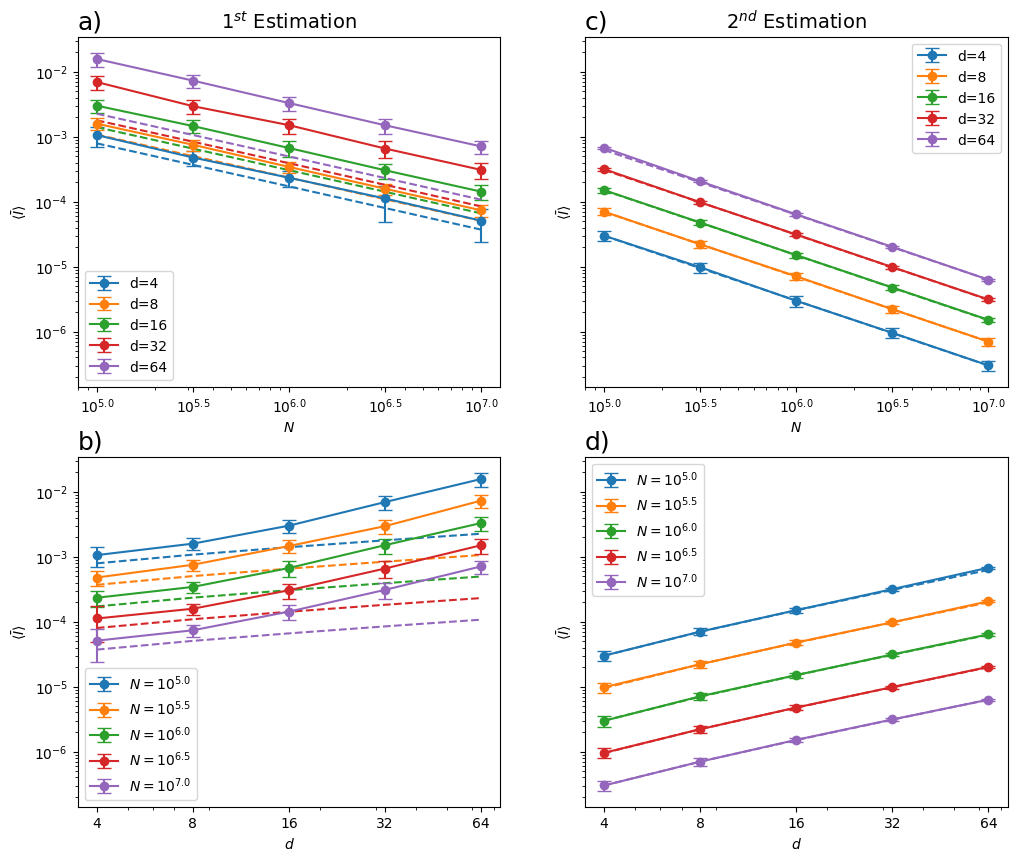

In [6]:
fig, axs = plt.subplots(2, 2, figsize=(12, 10) , sharey=True)
#fig.suptitle(r"Shot inicial $10d$ y $N_1 = ((d-1)(2d-1)/4)^{1/3} N^{2/3}$, $100$ estados puros aleatorios", fontsize=14)


## Graphs on the top
## Graph on the left

i = 0
for d in dimensiones:
    axs[0 , 0].errorbar(10**potencias, np.ones(len(potencias))-fid1_means_N[d], yerr=fid1_stds_N[d], color = colores[i], label=f'd={d}', marker='o', capsize=5)
    axs[0 , 0].plot( 10**potencias , GM(d , N(potencias,d)), color = colores[i], linestyle='--')
    i += 1

axs[0 , 0].set_xlabel('$N$')
axs[0 , 0].set_ylabel(r'$ \langle\bar{I}\rangle $')
axs[0, 0].set_title('a)', loc='left', fontsize='18')
axs[0 , 0].set_title('$1^{st}$ Estimation', fontsize='14')

axs[0 , 0].set_xscale('log') 
axs[0 , 0].set_yscale('log') 

axs[0 , 0].set_xticks(10**potencias) 
axs[0 , 0].set_xticklabels([fr'$10^{{{n}}}$' for n in potencias], fontsize=10)

axs[0 , 0].legend()
axs[0 , 0].grid(True)


## Graph on the right

i = 0
for d in dimensiones:
    axs[0 , 1].errorbar(10**potencias, np.ones(len(potencias))-fid2_means_N[d], yerr=fid2_stds_N[d], color = colores[i], label=f'd={d}', marker='o', capsize=5)
    axs[0 , 1].plot( 10**potencias , GM(d , 10**potencias), color = colores[i], linestyle='--')
    i += 1

axs[0 , 1].set_xlabel('$N$')
axs[0 , 1].set_ylabel(r'$ \langle\bar{I}\rangle $')
axs[0 , 1].set_title('c)', loc='left', fontsize='18')
axs[0 , 1].set_title('$2^{nd}$ Estimation', fontsize='14')

axs[0 , 1].set_xscale('log')  # escala logarítmica en eje x
axs[0 , 1].set_yscale('log') 

axs[0 , 1].set_xticks(10**potencias) 
axs[0 , 1].set_xticklabels([fr'$10^{{{n}}}$' for n in potencias], fontsize=10)

axs[0 , 1].legend()
axs[0 , 1].grid()

##############################################################################################################

## Graphs on the bottom
## Left graph

i = 0
for n in potencias:
    axs[ 1 , 0 ].errorbar(dimensiones, np.ones(len(dimensiones))-fid1_means_d[n], yerr=fid1_stds_d[n], color = colores[i], label=fr'$N=10^{{{n}}}$', marker='o', capsize=5)
    axs[ 1 , 0 ].plot( dimensiones , GM(dimensiones , N(n,dimensiones)), color = colores[i], linestyle='--')
    i += 1

axs[ 1 , 0 ].set_xlabel('$d$')
axs[ 1 , 0 ].set_ylabel(r'$ \langle\bar{I}\rangle $')
axs[ 1 , 0].set_title('b)', loc='left', fontsize='18')
#axs[ 1 , 0 ].set_title('Fidelidad media primera etapa vs d para diferentes N')

axs[ 1 , 0 ].set_xscale('log')  # escala logarítmica en eje x
axs[ 1 , 0 ].set_yscale('log') 

axs[1 , 0].set_xticks(dimensiones) 
axs[1 , 0].set_xticklabels(dimensiones, fontsize=10)

axs[ 1 , 0 ].legend()
axs[ 1 , 0 ].grid(True)

## Right graph

i = 0
for n in potencias:
    axs[1 , 1].errorbar(dimensiones, np.ones(len(dimensiones))-fid2_means_d[n], yerr=fid2_stds_d[n], color = colores[i], label=fr'$N=10^{{{n}}}$', marker='o', capsize=5)
    axs[1 , 1].plot( dimensiones , GM(dimensiones , 10**n), color = colores[i], linestyle='--')
    i += 1

axs[1 , 1].set_xlabel('$d$')
axs[1 , 1].set_ylabel(r'$ \langle\bar{I}\rangle $')
axs[1 , 1].set_title('d)', loc='left', fontsize='18')
#axs[1 , 1].set_title('Fidelidad media final vs d para diferentes N')

axs[1 , 1].set_xscale('log')  # escala logarítmica en eje x
axs[1 , 1].set_yscale('log') 

axs[1 , 1].set_xticks(dimensiones) 
axs[1 , 1].set_xticklabels(dimensiones, fontsize=10)

axs[1 , 1].legend()
axs[1 , 1].grid(True)

#quitar grids
axs[0,0].grid(False)
axs[0,1].grid(False)
axs[1,0].grid(False)
axs[1,1].grid(False)

plt.savefig('PureState.pdf', bbox_inches='tight')


## 4. Curve fits

We performed curve fitting of the plotted data considering the following model
$$

I = \alpha \frac{(d-1)^\gamma}{N^\beta}.

$$

To find the values of $\beta, \gamma$ we perform linear curve adjustments considering the logarithm of the previous function,
$$
\log(I) = \log(\alpha) - \beta \log(N) + \gamma \log(d-1).
$$
For the $\beta$ fittings, we set the values of the ensemble. For the $\gamma$ fittings we set the dimension value. Finally, for the $\alpha$ adjustment, we consider the average of the adjusted values.

### 4.1 For each dimension, adjust the ensemble vs. infidelity curve. We found the values of $\beta$.

In [23]:
betas1 = []
betas2 = []

for d in dimensiones:

    #first estimation
    xdata1 = np.log10(((d-1)*(2*d-1)/4)**(1/3) * 10**(2*potencias/3) + 10*d) 
    ydata1 = np.log10(np.ones(len(potencias))-fid1_means_N[d])

    params , cov = np.polyfit(xdata1, ydata1, 1, cov=True)  # grado 1 = lineal

    a_fit_1 , b_fit_1 = params
    a_err_1 , b_err_1 = np.sqrt(np.diag(cov))

    betas1.append([d , -a_fit_1, a_err_1])  # Store both the slope and its error
    

    #second estimation
    xdata2 = np.log10(10**potencias) #second estimation
    ydata2 = np.log10(np.ones(len(potencias))-fid2_means_N[d])

    params , cov = np.polyfit(xdata2, ydata2, 1, cov=True)  # grado 1 = lineal

    a_fit_2 , b_fit_2 = params
    a_err_2 , b_err_2 = np.sqrt(np.diag(cov))

    betas2.append([d , -a_fit_2, a_err_2])  # Store both the slope and its error
    

mean_beta1 = np.mean([beta[1] for beta in betas1])
mean_beta2 = np.mean([beta[1] for beta in betas2])

# Print the results

print('First estimation:')
for i in range(len(dimensiones)):    
    print(f'd={dimensiones[i]}, beta={betas1[i][1]}, std={betas1[i][2]}')

print(f'Mean beta = {mean_beta1:.3f}')

print('Second estimation:')
for i in range(len(dimensiones)):    
    print(f'd={dimensiones[i]}, beta={betas2[i][1]}, std={betas2[i][2]}')

print(f'Mean beta = {mean_beta2:.3f}')


First estimation:
d=4, beta=0.9832807341536233, std=0.010007726317640376
d=8, beta=1.0073917437600224, std=0.003536705133537453
d=16, beta=1.00317176543935, std=0.00767958299413758
d=32, beta=1.0128920761589688, std=0.018650645919761247
d=64, beta=1.0207919520811453, std=0.0064060227700740826
Mean beta = 1.006
Second estimation:
d=4, beta=1.0016559592460588, std=0.004908316002190135
d=8, beta=1.001269066966754, std=0.0021599941353278107
d=16, beta=0.9992395837160454, std=0.0007902147532635875
d=32, beta=1.0026095954525889, std=0.0026410492877744747
d=64, beta=1.0152134672037199, std=0.003537579933242457
Mean beta = 1.004


### 4.2 For each ensemble adjust dimension curve vs infidelity. We find the values of $\gamma$.

In [42]:
gammas1 = []
gammas2 = []

for n in potencias:
    n_size = N(n,dimensiones) + 10*dimensiones

    #First estimation
    xdata1 = np.log10(dimensiones-1)
    ydata1 = np.log10(n_size*(np.ones(len(dimensiones))-fid1_means_d[n]))

    params1 , cov1 = np.polyfit(xdata1, ydata1, 1, cov=True)  # grado 1 = lineal

    a_fit1 , b_fit1 = params1
    a_err1 , b_err1 = np.sqrt(np.diag(cov1))

    gammas1.append([n, a_fit1, a_err1])  # Store both the slope and its error

    #Second estimation
    xdata2 = np.log10(dimensiones-1)
    ydata2 = np.log10((np.ones(len(dimensiones))-fid2_means_d[n]))

    params2 , cov2 = np.polyfit(xdata2, ydata2, 1, cov=True)  # grado 1 = lineal

    a_fit2 , b_fit2 = params2
    a_err2 , b_err2 = np.sqrt(np.diag(cov2))
    gammas2.append([n, a_fit2, a_err2])  # Store both the slope and its error
    

mean_gamma1 = np.mean([gamma[1] for gamma in gammas1])
mean_gamma2 = np.mean([gamma[1] for gamma in gammas2])

#Print the results

print('First estimation:')
for i in range(len(potencias)):    
    print(f'n={potencias[i]}, gamma={gammas1[i][1]}, std={gammas1[i][2]}')

print(f'Mean gamma = {mean_gamma1:.3f}')


print('Second estimation:')
for i in range(len(potencias)):    
    print(f'n={potencias[i]}, gamma={gammas2[i][1]}, std={gammas2[i][2]}')

print(f'Mean gamma = {mean_gamma2:.3f}')



First estimation:
n=5.0, gamma=1.5569194393125765, std=0.09145146787954564
n=5.5, gamma=1.5489551165025532, std=0.08371991588931493
n=6.0, gamma=1.5417712571091124, std=0.08712629022222922
n=6.5, gamma=1.5197717382685518, std=0.09356826974861307
n=7.0, gamma=1.5305670136903027, std=0.09112083580606845
Mean gamma = 1.540
Second estimation:
n=5.0, gamma=1.0219637579361203, std=0.007967873959121501
n=5.5, gamma=0.9998218363653494, std=0.008474793253471878
n=6.0, gamma=1.0054302819910599, std=0.0034679833444997256
n=6.5, gamma=1.0014376817628559, std=0.002310831754943441
n=7.0, gamma=1.000191335394793, std=0.002539589625127152
Mean gamma = 1.006


### 4.3 Perform cruvefit to find the values of $\alpha$ using as values of $\beta$ and $\gamma$ the average of the values found in the previous fittings.

In [ ]:
## ajuste por dimension

alphas1 = []
alphas2 = []

for d in dimensiones:

    # First estimation
    xdata1 = np.log10(((d-1)*(2*d-1)/4)**(1/3) * 10**(2*potencias/3) + 10*d) 
    ydata1 = np.ones(len(potencias))-fid1_means_N[d]

    def modelo(potencia , alpha):
        return alpha*(d-1)**(mean_gamma1)/(10**potencia)**(mean_beta1)
    
    params, cov = curve_fit(modelo, xdata1, ydata1)
    alphas1.append([n, params, np.sqrt(np.diag(cov))])  # Store both the slope and its error

    # Second estimation
    xdata2 = np.log10(10**potencias + 10*d) #second estimation
    ydata2 = np.ones(len(potencias))-fid2_means_N[d]

    def modelo(potencia , alpha):
        return alpha*(d-1)**(mean_gamma2)/(10**potencia)**(mean_beta2)
    
    params, cov = curve_fit(modelo, xdata2, ydata2)

    alphas2.append([n,params, np.sqrt(np.diag(cov))])  # Store both the slope and its error

# Print the results

mean_alpha1 = np.mean([alpha[1] for alpha in alphas1])
mean_alpha2 = np.mean([alpha[1] for alpha in alphas2])

print('First estimation:')
for i in range(len(potencias)):    
    print(f'n={potencias[i]}, alpha={alphas1[i][1]}, std={alphas1[i][2]}')

print(f'Mean alpha = {mean_alpha1:.3f}')    

print('Second estimation:')
for i in range(len(potencias)):    
    print(f'n={potencias[i]}, alpha={alphas2[i][1]}, std={alphas2[i][2]}')

print(f'Mean alpha = {mean_alpha2:.3f}')

First estimation:
n=5.0, alpha=[0.77224086], std=[0.00509036]
n=5.5, alpha=[0.54369221], std=[0.0016478]
n=6.0, alpha=[0.52824464], std=[0.0043348]
n=6.5, alpha=[0.63267856], std=[0.01077696]
n=7.0, alpha=[0.78494511], std=[0.00329418]
Mean alpha = 0.652
Second estimation:
n=5.0, alpha=[1.05058873], std=[0.00574056]
n=5.5, alpha=[1.05390317], std=[0.00099812]
n=6.0, alpha=[1.05508633], std=[0.00100864]
n=6.5, alpha=[1.07379445], std=[0.00345918]
n=7.0, alpha=[1.13124841], std=[0.00716352]
Mean alpha = 1.073
